# §7 Experiments and Block Ablation (Stage S7)

Here the model is used as a **measuring instrument** for the data-preparation decisions of §6. One
estimator (L2 logistic regression with C frozen) is applied to every arm on the same stored folds, and
each block is judged against its locked hypothesis with paired intervals. Results are reported on two
populations with equal weight:

* **E-ALL** – everyone in the training part, label `L_comb` (84 % of the positives already know they have
  diabetes);
* **E-SCREEN** – people *not* told they have diabetes, positive = HbA1c ≥ 6.5 % (the screening use case).

The 20 % hold-out is **not** evaluated here; its single use belongs to S9 after `exp-freeze`.

Contents: 1 splits · 2 data-justified model choice · 3 C0 · 4 arms run · 5 leak gate · 6 baselines on
E-SCREEN · 7 cumulative path · 8 leave-one-block-out · 9 E-ALL vs E-SCREEN · 10 PR and calibration ·
11 coefficient stability · 12 verdicts · 13 storage

In [1]:
import sys, pathlib
_here = pathlib.Path.cwd()
ROOT = next(p for p in [_here, *_here.parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))
from src import config as C, plots, results_io as R

import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from scipy import stats

from src import nhanes_io as io, labels as L, prep as P, evalkit as ek

pd.set_option("display.width", 170, "display.max_columns", 30, "display.max_colwidth", 70)
OUT = C.RESULTS_DIR / "S7"
OUT.mkdir(parents=True, exist_ok=True)
import os
os.environ.setdefault("PYTHONWARNINGS", "ignore::UserWarning")   # silence worker-side solver warnings (counted in run_arm_cv)
N_JOBS = min(12, max(1, (os.cpu_count() or 2) - 2))
S7 = {"mode": C.NB_MODE, "cv": f"{C.CV_SPLITS}x{C.CV_REPEATS}", "n_boot": C.N_BOOT, "n_boot_coef": C.N_BOOT_COEF}
T_START = time.time()
print(f"mode {C.NB_MODE}: {C.CV_SPLITS}x{C.CV_REPEATS} CV, B = {C.N_BOOT}, coefficient bootstrap B = {C.N_BOOT_COEF}, {N_JOBS} workers")

mode FINAL: 5x5 CV, B = 1000, coefficient bootstrap B = 500, 12 workers


## 1 Splits
**Why.** Every arm must be scored on identical folds, otherwise paired differences mix model effects with
split noise. The hold-out (label × race stratified, 20 %) and the repeated stratified folds are generated
once by `evalkit`, stored with SHA-256 hashes and re-verified on every run. Folds are stratified on the
four 3 × 3 strata (uncontrolled / controlled / undiagnosed / non-diabetic) so that each fold holds a fair
share of the 152 undiagnosed cases that define E-SCREEN.

In [2]:
raw = P.raw_cohort()
clean = L.add_labels(io.build_cohort())
assert (raw["SEQN"].to_numpy() == clean["SEQN"].to_numpy()).all()
tr, te = ek.make_holdout(clean)
raw_tr = raw.iloc[tr].reset_index(drop=True)
cl = clean.iloc[tr].reset_index(drop=True)
X = {1: P.raw_feature_frame(raw_tr, 1), 2: P.raw_feature_frame(raw_tr, 2)}
y = cl["L_comb"].to_numpy()
esc = cl["in_escreen"].eq(1).to_numpy()
y_esc = cl["y_escreen"].fillna(0).astype(int).to_numpy()   # only scored inside the E-SCREEN mask
strat = cl["stratum_3x3"].astype(str).to_numpy()
folds = ek.make_folds(y, strat)
n = len(y)
n_test_fold = n / C.CV_SPLITS
n_train_fold = n - n_test_fold
hold = json.loads((C.RESULTS_DIR / "splits" / "holdout.json").read_text(encoding="utf-8"))
print(f"training part {n:,} rows ({y.sum()} L_comb positives); hold-out {len(te):,} rows - not evaluated in S7")
print(f"E-SCREEN in training part: {esc.sum():,} rows, {y_esc[esc].sum()} positives (HbA1c >= 6.5, not diagnosed)")
print(f"folds: {len(folds)} = {folds.n_splits} x {folds.n_repeats}, hash {folds.hash[:16]}..., file {folds.path.name}")
print(f"hold-out test SEQN SHA-256 {hold['sha256_test_seqn'][:16]}...")
per_fold = pd.DataFrame([{"fold": i, "n_test": len(t), "pos_eall": int(y[t].sum()), "pos_escreen": int(y_esc[t][esc[t]].sum())}
                         for i, (_, t) in enumerate(folds)])
print(per_fold.describe().loc[["min", "mean", "max"], ["n_test", "pos_eall", "pos_escreen"]].round(1).to_string())
S7["splits"] = dict(n_train=n, n_holdout=len(te), n_pos_eall=int(y.sum()), n_escreen=int(esc.sum()),
                    n_pos_escreen=int(y_esc[esc].sum()), folds_hash=folds.hash, folds_file=folds.path.name,
                    holdout_sha256=hold["sha256_test_seqn"], pos_escreen_per_fold_min=int(per_fold["pos_escreen"].min()))

training part 4,584 rows (777 L_comb positives); hold-out 1,146 rows - not evaluated in S7
E-SCREEN in training part: 3,934 rows, 127 positives (HbA1c >= 6.5, not diagnosed)
folds: 25 = 5 x 5, hash 0d20f8f706ebf1e1..., file folds_FINAL.npz
hold-out test SEQN SHA-256 616fd0590bec7b92...
      n_test  pos_eall  pos_escreen
min    916.0     155.0         25.0
mean   916.8     155.4         25.4
max    917.0     156.0         26.0


**So what.** Each fold holds about 155 E-ALL positives but only about 24 E-SCREEN positives. That is why the
protocol scores E-SCREEN on the pooled out-of-fold vector (paired bootstrap), not fold by fold, and why most
E-SCREEN verdicts are expected to be inconclusive. The hold-out hash is printed so that S9 can prove it was
untouched.

## 2 Data-justified model choice
**Why.** Only basic interpretable models are allowed (HR3). Within that constraint each modelling choice
is tied to a diagnostic number from S4 (the DAJ table) – and the reason for *not* choosing an alternative.

In [3]:
S4dir = C.RESULTS_DIR / "S4"
lin = pd.read_csv(S4dir / "linearity_tests.csv")
inter = pd.read_csv(S4dir / "interaction_tests.csv")
daj = pd.read_csv(S4dir / "daj_table.csv")
vif4 = pd.read_csv(S4dir / "vif_table.csv")
print("S4 RCS linearity tests (4 knots vs linear, df 2):")
print(lin[["label", "n", "n_events", "chi2", "p", "nonlinear"]].round(4).to_string(index=False))
print("\nS4 interaction tests (primary spec A):")
print(inter[inter["spec"] == "A_primary"][["term", "chi2", "df", "p", "verdict"]].round(4).to_string(index=False))
sx = inter[inter["term"] == "sex_x_bmi"].set_index("spec")["p"].round(3).to_dict()
epv_den = {t: P.build_pipeline(P.ARMS["S"], t)[:-1].fit_transform(X[t]).shape[1] for t in (1, 2)}
epv = {t: round(y.sum() / k, 1) for t, k in epv_den.items()}
print(f"\nsex x BMI by spec: {sx}")
print(f"events per parameter in S: Tier 1 {y.sum()}/{epv_den[1]} = {epv[1]}, Tier 2 {y.sum()}/{epv_den[2]} = {epv[2]}")
print(f"imbalance: prevalence {y.mean():.3f} in the training part")
choice = pd.DataFrame([
    ("non-linearity", "age chi2 57.6, BMI 11.6, HDL 18.5, TC 41.8 (p < 0.01)", "L2 logistic regression + B-spline basis (P13)", "categorised bands (arbitrary cut-points, information loss); GAM / boosting (outside HR3)"),
    ("interactions", "race x BMI p 0.39, Asian x BMI p 0.93 (MDE 0.70 log-OR)", "no interaction terms; Asian BMI bias treated as a measurement issue (P14, S8)", "interaction terms add variance without detectable gain"),
    ("collinearity", "weight VIF 95.7, BMI 97.6; 6 BP readings 8.8-11.7", "aggregate + in-fold VIF pruning (P04/P05), L2 as second defence", "L1 (unstable selection among collinear columns, sensitivity only)"),
    ("sample size", f"{y.sum()} events / {epv_den[1]} parameters (EPV {epv[1]})", "unpenalised fit would be acceptable; mild L2 (C0) chosen by inner CV", "deep trees / ensembles (overfit, HR3)"),
    ("imbalance", f"prevalence {y.mean():.1%}", "no resampling; class_weight tested as block B6a", "SMOTE (breaks calibration and the survey design)"),
    ("thresholds / leakage", "clinical cut-points and leakage need inspection", "depth-3 tree (min leaf 50) as a probe only", "tree as main model (step functions, unstable)"),
], columns=["diagnostic", "evidence (S4 / S7)", "decision", "why not the alternative"])
choice.to_csv(OUT / "model_choice.csv", index=False)
print(choice.to_string(index=False))
S7["model_choice"] = dict(linearity=lin.set_index("label")[["chi2", "p"]].round(4).to_dict("index"),
                          sex_x_bmi_p_by_spec=sx, epv=epv, n_params=epv_den)

S4 RCS linearity tests (4 knots vs linear, df 2):
            label    n  n_events    chi2      p  nonlinear
              age 4478       722 57.6075 0.0000       True
              BMI 4478       722 11.5618 0.0031       True
            waist 4478       722  7.0540 0.0294       True
       SBP (mean) 4478       722  5.8698 0.0531      False
              HDL 4478       722 18.4670 0.0001       True
total cholesterol 4478       722 41.7673 0.0000       True
              PIR 4478       722  0.8344 0.6589      False

S4 interaction tests (primary spec A):
       term   chi2  df      p      verdict
 race_x_bmi 5.1890   5 0.3933 not detected
asian_x_bmi 0.0071   1 0.9328 not detected
  age_x_bmi 0.5829   1 0.4452 not detected
  sex_x_bmi 6.9951   1 0.0082     detected



sex x BMI by spec: {'A_primary': 0.008, 'B_minimal': 0.833, 'C_splines': 0.072}
events per parameter in S: Tier 1 777/42 = 18.5, Tier 2 777/53 = 14.7
imbalance: prevalence 0.170 in the training part
          diagnostic                                      evidence (S4 / S7)                                                                      decision                                                                  why not the alternative
       non-linearity   age chi2 57.6, BMI 11.6, HDL 18.5, TC 41.8 (p < 0.01)                                 L2 logistic regression + B-spline basis (P13) categorised bands (arbitrary cut-points, information loss); GAM / boosting (outside HR3)
        interactions race x BMI p 0.39, Asian x BMI p 0.93 (MDE 0.70 log-OR) no interaction terms; Asian BMI bias treated as a measurement issue (P14, S8)                                   interaction terms add variance without detectable gain
        collinearity       weight VIF 95.7, BMI 97.6; 6 BP readings 

**So what.** Age, BMI and both lipids bend significantly, so the main model is a GLM with spline terms rather than
a linear logit; the linear version stays as the ablation arm *S-linear*. Race × BMI and Asian × BMI are not
detected (underpowered – "not detected" is not "absent"). One caveat is reported, not hidden: S4 found
sex × BMI significant in its primary specification (p printed above) but not in the minimal or spline
specifications; because the result depends on the specification, no interaction term is added and the point is
listed as a limitation. With about 18 events per parameter, overfitting risk is modest; L2 mainly stabilises
correlated anthropometrics. Redundancy is handled as in the S4 DAJ table: in-fold iterative VIF > 10 pruning with
BMI and waist protected (P05), which removes only weight (§6.5); height, hip and arm therefore stay in S.

## 3 Regularisation strength C0
**Why.** HR2 requires the *same model* for minimal and systematic arms. C is therefore chosen once – by
`LogisticRegressionCV(Cs=[0.01, 0.1, 1, 10])`, inner 5-fold ROC-AUC, on the S arm of Tier 1 with its class and
survey weights – and then frozen for every arm. Choosing it on S favours S slightly (the other arms do not get
their own tuning); M0 with its own C is an S9 sensitivity.

In [4]:
from sklearn.linear_model import LogisticRegressionCV
from sklearn.model_selection import StratifiedKFold

cfgS = P.ARMS["S"]
design = P.build_pipeline(cfgS, 1)[:-1].fit_transform(X[1])
ylab = P.training_label(raw_tr, cfgS)
inner = StratifiedKFold(5, shuffle=True, random_state=ek.derive_seed(C.SEED_MASTER, "S7", "C0"))
with warnings.catch_warnings():
    warnings.simplefilter("ignore", FutureWarning)
    lrcv = LogisticRegressionCV(Cs=[0.01, 0.1, 1, 10], cv=inner, scoring="roc_auc", max_iter=C.LR_MAX_ITER,
                                class_weight="balanced", l1_ratios=(0.0,), use_legacy_attributes=False)
    lrcv.fit(design, ylab, sample_weight=P.survey_weights(raw_tr))
scores = np.asarray(lrcv.scores_).reshape(5, -1)   # (inner folds, Cs); l1_ratio fixed at 0 (pure L2)
C0 = float(np.ravel(lrcv.C_)[0])
cv_auc = pd.Series(scores.mean(axis=0).ravel()[:4], index=[0.01, 0.1, 1, 10]).round(4)
print("inner-CV ROC-AUC by C:"); print(cv_auc.to_string())
print(f"C0 = {C0} (frozen for all arms and tiers)")
S7["C0"] = dict(C0=C0, inner_cv_auc=cv_auc.to_dict())

inner-CV ROC-AUC by C:
0.01     0.8490
0.10     0.8519
1.00     0.8515
10.00    0.8514
C0 = 0.1 (frozen for all arms and tiers)


**So what.** The inner-CV AUC is almost flat across C (differences in the third decimal), so the choice of C is not a
lever for the results below; C0 is used for every arm. The flatness also limits the optimistic bias of tuning on S.

## 4 Running the arms
**Why.** Each arm × tier is cross-validated on the stored folds with the frozen C0; every preparation step is
refitted inside each training fold. Arms with P02 off are trained on their own naive label (965 positives),
but every arm is scored against the frozen `L_comb`. The depth-3 tree is run on M0, M1 and S as a probe.
Solver non-convergence (the unscaled arms) is counted, not suppressed.

In [5]:
ARM_LIST = list(P.ARMS)
jobs = [(a, t, "lr") for t in (1, 2) for a in ARM_LIST] + [(a, t, "tree") for t in (1, 2) for a in ("M0", "M1", "S")]
t0 = time.time()
runs = Parallel(n_jobs=N_JOBS)(delayed(P.run_arm_cv)(a, t, X[t], raw_tr, folds, C_=C0, model=m) for a, t, m in jobs)
OOF = {(r["arm"], r["tier"], r["model"]): r["oof"] for r in runs}
PM = {k: ek.mean_oof(v, n) for k, v in OOF.items()}          # repeat-averaged OOF probability per row
diag = pd.DataFrame([{k: r[k] for k in ("arm", "tier", "model", "n_convergence_warnings", "seconds", "n_pos_train_label")}
                     for r in runs])
assert all(np.isfinite(v).all() for v in PM.values())
for r in runs:   # no hold-out row can appear: OOF rows index the training part only
    assert r["oof"]["row"].max() < n and r["oof"].groupby("repeat")["row"].nunique().eq(n).all()
print(f"{len(jobs)} arm x tier x model runs, {sum(len(f) for f in [folds]) * len(jobs)} fits, {time.time() - t0:.0f} s wall")
print(diag[diag["n_convergence_warnings"] > 0].to_string(index=False))
S7["runs"] = dict(n_runs=len(jobs), wall_seconds=time.time() - t0,
                  convergence=diag[diag["n_convergence_warnings"] > 0][["arm", "tier", "model", "n_convergence_warnings"]].to_dict("records"))

44 arm x tier x model runs, 1100 fits, 112 s wall
   arm  tier model  n_convergence_warnings   seconds  n_pos_train_label
    M0     1    lr                      25 84.179252                772
    M1     1    lr                      25 74.611674                772
cum+B1     1    lr                      25 73.716814                777
cum+B3     1    lr                      25 65.289050                777
cum+B4     1    lr                      25 67.354725                777
  S-B5     1    lr                      25 66.254693                777
    M0     2    lr                      24 74.316970                772
    M1     2    lr                      25 67.436307                772
cum+B1     2    lr                      25 66.394406                777
cum+B3     2    lr                      25 62.579825                777
cum+B4     2    lr                      25 61.976806                777
  S-B5     2    lr                      25 35.718114                777


In [6]:
from sklearn.metrics import roc_auc_score, average_precision_score

def pop_of(name):
    """(label vector, evaluation mask) of a population."""
    if name == "E-ALL":
        return y, np.ones(n, bool)
    if name == "E-SCREEN":
        return y_esc, esc
    if name == "PIR-missing":
        return y, cl["INDFMPIR"].isna().to_numpy()
    raise ValueError(name)

def _bacc05(yy, pp):
    pred = pp >= 0.5
    return 0.5 * (pred[yy == 1].mean() + (~pred[yy == 0]).mean())

def _calslope_dev(yy, pp):
    return abs(ek._calibration(yy, pp)[0] - 1.0)

METRIC_FN = {"roc_auc": roc_auc_score, "pr_auc": average_precision_score,
             "brier": lambda yy, pp: float(np.mean((pp - yy) ** 2)),
             "bacc05": _bacc05, "calslope_dev": _calslope_dev}

def auc_ci(p, pop="E-ALL", seed_tag="auc"):
    """AUC of a pooled OOF vector with a label-stratified bootstrap CI (paired against a constant 0.5)."""
    yy, m = pop_of(pop)
    b = ek.paired_bootstrap(yy, p, np.full(n, 0.5), "roc_auc", n_boot=C.N_BOOT, eval_mask=m,
                            seed=ek.derive_seed(C.SEED_MASTER, "S7", seed_tag, pop))
    return b["metric_a"], b["ci_low"] + 0.5, b["ci_high"] + 0.5

def arm_row(key):
    oof, pm = OOF[key], PM[key]
    fm = ek.fold_metrics(oof, y)
    out = {"arm": key[0], "tier": key[1], "model": key[2], "eall_auc_foldmean": fm["roc_auc"].mean(),
           "eall_auc_foldsd": fm["roc_auc"].std(ddof=1)}
    for pop in ("E-ALL", "E-SCREEN"):
        yy, m = pop_of(pop)
        ms = ek.metric_suite(yy[m], pm[m])
        a, lo, hi = auc_ci(pm, pop, seed_tag=f"{key}")
        tag = "eall" if pop == "E-ALL" else "escr"
        out.update({f"{tag}_auc": a, f"{tag}_auc_lo": lo, f"{tag}_auc_hi": hi, f"{tag}_pr_auc": ms["pr_auc"],
                    f"{tag}_brier": ms["brier"], f"{tag}_recall_spec80": ms["recall_at_spec"],
                    f"{tag}_cal_slope": ms["cal_slope"], f"{tag}_cal_citl": ms["cal_citl"], f"{tag}_prev": ms["prevalence"]})
    out["eall_auc_weighted"] = ek.metric_suite(y, pm, w=cl[C.WEIGHT_PHLEB].to_numpy())["roc_auc"]
    return out

arm_metrics = pd.DataFrame([arm_row(k) for k in OOF]).merge(diag, on=["arm", "tier", "model"])
arm_metrics.to_csv(OUT / "arm_metrics.csv", index=False)
show = ["arm", "tier", "model", "eall_auc", "eall_auc_lo", "eall_auc_hi", "escr_auc", "escr_auc_lo", "escr_auc_hi",
        "eall_brier", "escr_recall_spec80", "eall_cal_slope", "n_convergence_warnings"]
print(arm_metrics[show].round(3).to_string(index=False))

          arm  tier model  eall_auc  eall_auc_lo  eall_auc_hi  escr_auc  escr_auc_lo  escr_auc_hi  eall_brier  escr_recall_spec80  eall_cal_slope  n_convergence_warnings
           M0     1    lr     0.961        0.952        0.968     0.844        0.808        0.881       0.040               0.709           1.195                      25
           M1     1    lr     0.828        0.814        0.843     0.772        0.739        0.804       0.112               0.535           0.961                      25
            S     1    lr     0.836        0.822        0.849     0.781        0.748        0.809       0.185               0.520           0.867                       0
       cum+B1     1    lr     0.829        0.815        0.844     0.775        0.744        0.807       0.112               0.543           0.962                      25
       cum+B3     1    lr     0.831        0.816        0.845     0.779        0.749        0.810       0.112               0.551           0.988     

**So what.** The table is the raw material for everything below; the paired comparisons that follow are what
decides. Three patterns are already visible: the naive arm M0 reaches an E-ALL AUC near 0.96 that collapses once the
availability rule is applied; all admissible arms sit in a narrow band; and every arm loses discrimination when
moved from E-ALL to E-SCREEN. Only the unscaled arms (M0, M1, cumulative steps before B5, S−B5) hit the
iteration limit, which is itself a cost of skipping scaling.

### Comparison engine
Paired difference A − B of a metric on a population: fold-level Nadeau–Bengio corrected t and a paired,
label-stratified bootstrap on the repeat-averaged OOF vectors; on E-ALL the **wider** interval is used, on
E-SCREEN the bootstrap only. The 80 %-power minimal detectable difference (MDD) is reported with each Δ. Verdict
rules are those locked in `governance/hypotheses.md`; for a directional claim an `evalkit` verdict of
"equivalent" (CI inside ±magnitude) means the claimed magnitude is excluded and is recorded as **refuted**.

In [7]:
def fold_values(key, metric, pop):
    yy, m = pop_of(pop)
    fn = METRIC_FN[metric]
    vals = {}
    for (r, f), g in OOF[key].groupby(["repeat", "fold"]):
        rows = g["row"].to_numpy()
        keep = m[rows]
        vals[(r, f)] = fn(yy[rows][keep], g["prob"].to_numpy()[keep])
    return pd.Series(vals)

def compare(a, b, tier=1, metric="roc_auc", pop="E-ALL", model="lr", pa=None, pb=None):
    """Paired comparison A - B; pa/pb override the OOF vectors (baselines)."""
    yy, m = pop_of(pop)
    pa = PM[(a, tier, model)] if pa is None else pa
    pb = PM[(b, tier, model)] if pb is None else pb
    bm = metric if metric in ("roc_auc", "brier", "pr_auc") else METRIC_FN[metric]
    bs = ek.paired_bootstrap(yy, pa, pb, bm, n_boot=C.N_BOOT, eval_mask=m,
                             seed=ek.derive_seed(C.SEED_MASTER, "S7", a, b, tier, metric, pop))
    row = dict(a=a, b=b, tier=tier, metric=metric, pop=pop, model=model, diff_pooled=bs["diff"],
               boot_lo=bs["ci_low"], boot_hi=bs["ci_high"], boot_se=bs["se"], n_eval=bs["n_eval"], n_pos=bs["n_pos"])
    if pop != "E-SCREEN" and (a, tier, model) in OOF and (b, tier, model) in OOF:
        d = (fold_values((a, tier, model), metric, pop) - fold_values((b, tier, model), metric, pop)).to_numpy()
        ct = ek.corrected_t(d, n_train_fold, n_test_fold)
        row.update(t_mean=ct["mean"], t_lo=ct["ci_low"], t_hi=ct["ci_high"], t_se=ct["se_corr"], t_p=ct["p"], J=ct["J"])
        use_t = (ct["ci_high"] - ct["ci_low"]) >= (bs["ci_high"] - bs["ci_low"])
        est, lo, hi, se = (ct["mean"], ct["ci_low"], ct["ci_high"], ct["se_corr"]) if use_t else (bs["diff"], bs["ci_low"], bs["ci_high"], bs["se"])
        mdd = (stats.t.ppf(0.975, ct["df"]) + stats.t.ppf(0.80, ct["df"])) * se
        row["interval"] = "corrected_t" if use_t else "bootstrap"
    else:
        est, lo, hi, se = bs["diff"], bs["ci_low"], bs["ci_high"], bs["se"]
        mdd = (stats.norm.ppf(0.975) + stats.norm.ppf(0.80)) * se
        row["interval"] = "bootstrap"
        if pop == "E-SCREEN" and (a, tier, model) in OOF and (b, tier, model) in OOF:
            ra = ek.repeat_metrics(OOF[(a, tier, model)], y_esc, eval_mask=esc).set_index("repeat")
            rb = ek.repeat_metrics(OOF[(b, tier, model)], y_esc, eval_mask=esc).set_index("repeat")
            if metric in ra:
                dr = ra[metric] - rb[metric]
                row.update(rep_min=dr.min(), rep_max=dr.max())
    row.update(est=est, lo=lo, hi=hi, se=se, mdd=mdd)
    return row

def v_equiv(lo, hi, s):
    return "supported" if (lo > -s and hi < s) else ("refuted" if (lo >= s or hi <= -s) else "inconclusive")

def v_dir(lo, hi, est, s, direction):
    v = ek.verdict(lo, hi, s, direction, est)
    return "refuted" if v == "equivalent" else v

def v_noninf(lo, hi, s):
    return "supported" if lo > -s else ("refuted" if hi < -s else "inconclusive")

COMP = []   # every comparison row, stored in results/S7/comparisons.csv

def cmp_(*args, label="", **kw):
    r = compare(*args, **kw)
    r["label"] = label
    COMP.append(r)
    return r

def fmt(r, k=3):
    return f"{r['est']:+.{k}f} [{r['lo']:+.{k}f}, {r['hi']:+.{k}f}] ({r['interval']}, MDD {r['mdd']:.{k}f})"

## 5 Leak gate: M0 → M1
**Why.** M0 keeps glucose, treatment, diagnosis history, prediabetes counselling (DIQ160) and prior glucose
testing (DIQ180). If the availability rule removes real leakage, discrimination must *drop* – a correct
deterioration (hypotheses H2a, B2). A depth-3 tree shows *where* the M0 signal comes from (B2t).

Tier 1 E-ALL    AUC M1 - M0 = -0.131 [-0.148, -0.114] (corrected_t, MDD 0.024)


Tier 1 E-SCREEN AUC M1 - M0 = -0.072 [-0.113, -0.031] (bootstrap, MDD 0.059)


Tier 2 E-ALL    AUC M1 - M0 = -0.119 [-0.133, -0.106] (corrected_t, MDD 0.019)


Tier 2 E-SCREEN AUC M1 - M0 = -0.081 [-0.120, -0.041] (bootstrap, MDD 0.056)


Tier 1 E-ALL    AUC S - (S-B2) = -0.122 [-0.138, -0.105] (corrected_t, MDD 0.023)


Tier 1 E-SCREEN AUC S - (S-B2) = -0.090 [-0.124, -0.060] (bootstrap, MDD 0.047)


   root_feature variable     role threshold                level2
M0   DIQ070_2.0   DIQ070     leak       0.5  [DIQ180_2.0, DID040]
M1   BPQ020_2.0   BPQ020  feature       0.5  [BMXWAIST, BMXWAIST]
S    BPQ020_1.0   BPQ020  feature       0.5  [BMXWAIST, BMXWAIST]
B2t verdict: supported


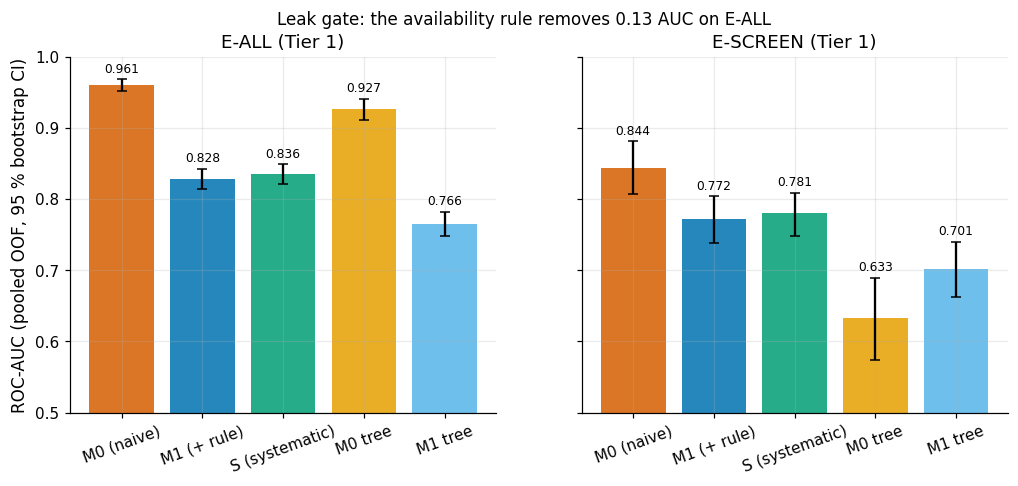

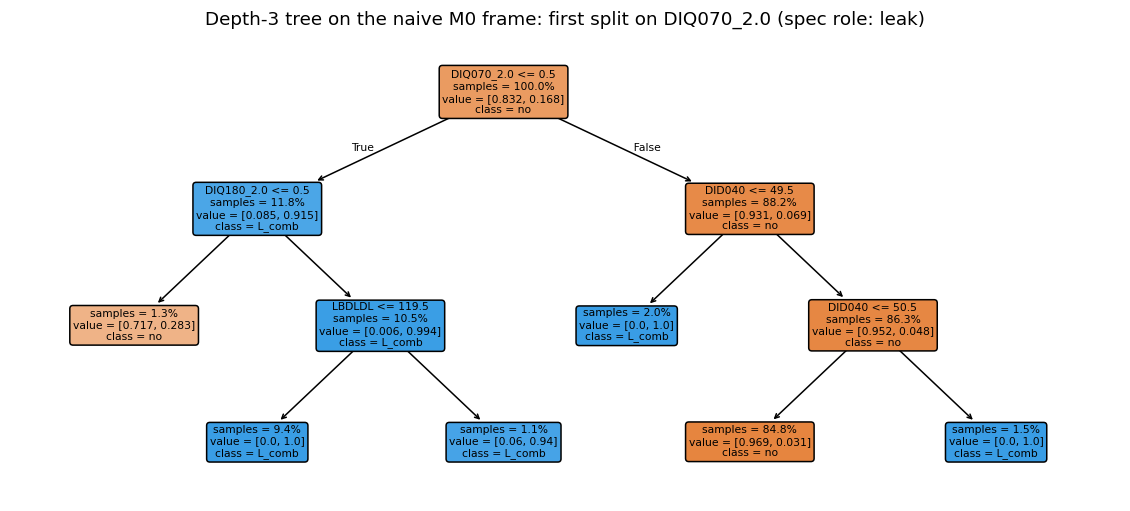

In [8]:
from sklearn.tree import plot_tree

gate = {}
for t in (1, 2):
    for pop in ("E-ALL", "E-SCREEN"):
        gate[(t, pop)] = cmp_("M1", "M0", t, "roc_auc", pop, label="B2 leak gate")
        print(f"Tier {t} {pop:8s} AUC M1 - M0 = {fmt(gate[(t, pop)])}")
for pop in ("E-ALL", "E-SCREEN"):
    r = cmp_("S", "S-B2", 1, "roc_auc", pop, label="B2 LOBO")
    print(f"Tier 1 {pop:8s} AUC S - (S-B2) = {fmt(r)}")

def base_var(name):
    for v in sorted(P._spec_by_var().index, key=len, reverse=True):
        if name == v or name.startswith(v + "_"):
            return v
    return name

roots, trees = {}, {}
for arm in ("M0", "M1", "S"):
    cfg = P.ARMS[arm]
    pipe = P.build_pipeline(cfg, 1, model="tree").fit(X[1], P.training_label(raw_tr, cfg), **P.fit_params(cfg, raw_tr))
    names = list(pipe[:-1].get_feature_names_out())
    tree = pipe[-1]
    trees[arm] = (tree, names)
    root = names[tree.tree_.feature[0]]
    rv = base_var(root)
    role = P._spec_by_var()["role"].get(rv, "derived")
    roots[arm] = dict(root_feature=root, variable=rv, role=role, threshold=float(tree.tree_.threshold[0]),
                      level2=[names[tree.tree_.feature[c]] for c in (tree.tree_.children_left[0], tree.tree_.children_right[0])
                              if tree.tree_.feature[c] >= 0])
print(pd.DataFrame(roots).T.to_string())
b2t = "supported" if roots["M0"]["role"] == "leak" and P._spec_by_var()["admissible"].get(roots["M1"]["variable"], "T1") != "N" else "refuted"
print(f"B2t verdict: {b2t}")
S7["leak_gate"] = {f"T{t}_{pop}": {k: gate[(t, pop)][k] for k in ("est", "lo", "hi", "interval", "mdd")} for (t, pop) in gate}
S7["tree_roots"] = roots

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
bars = [("M0", "lr", "M0 (naive)"), ("M1", "lr", "M1 (+ rule)"), ("S", "lr", "S (systematic)"), ("M0", "tree", "M0 tree"), ("M1", "tree", "M1 tree")]
colors = [C.OKABE_ITO["vermillion"], C.OKABE_ITO["blue"], C.OKABE_ITO["green"], C.OKABE_ITO["orange"], C.OKABE_ITO["sky"]]
for ax, pop, tag in zip(axes, ("E-ALL", "E-SCREEN"), ("eall", "escr")):
    sub = arm_metrics[arm_metrics["tier"] == 1].set_index(["arm", "model"])
    for i, ((a, m, _), c) in enumerate(zip(bars, colors)):
        v_ = sub.loc[(a, m)]
        ax.bar(i, v_[f"{tag}_auc"], color=c, alpha=0.85)
        ax.errorbar(i, v_[f"{tag}_auc"], yerr=[[v_[f"{tag}_auc"] - v_[f"{tag}_auc_lo"]], [v_[f"{tag}_auc_hi"] - v_[f"{tag}_auc"]]],
                    color="k", capsize=3)
        ax.text(i, v_[f"{tag}_auc_hi"] + 0.01, f"{v_[f'{tag}_auc']:.3f}", ha="center", fontsize=8)
    ax.set_xticks(range(len(bars)), [b[2] for b in bars], rotation=20)
    ax.set_ylim(0.5, 1.0)
    ax.set_title(f"{pop} (Tier 1)")
axes[0].set_ylabel("ROC-AUC (pooled OOF, 95 % bootstrap CI)")
fig.suptitle(f"Leak gate: the availability rule removes {-gate[(1, 'E-ALL')]['est']:.2f} AUC on E-ALL", fontsize=11)
plots.savefig(fig, "S7_leak_gate", caption="ROC-AUC of the naive arm M0, the availability-screened arm M1 and the systematic arm S "
              "(logistic regression) and of depth-3 trees, on E-ALL and E-SCREEN, Tier 1, with 95 % bootstrap CIs. "
              "The drop from M0 to M1 is the leakage removed by the availability rule.")
plt.show()

fig, ax = plt.subplots(figsize=(13, 5.5))
tree, names = trees["M0"]
plot_tree(tree, feature_names=names, class_names=["no", "L_comb"], filled=True, impurity=False, proportion=True,
          rounded=True, fontsize=7, ax=ax)
ax.set_title(f"Depth-3 tree on the naive M0 frame: first split on {roots['M0']['root_feature']} (spec role: {roots['M0']['role']})")
plots.savefig(fig, "S7_tree_m0", caption="Decision tree (depth 3, min leaf 50) fitted on the naive M0 feature frame (Tier 1, training part). "
              "The root split uses a variable that the availability rule removes.")
plt.show()

**So what.** The availability rule removes the "too-good-to-be-true" signal: on E-ALL the AUC falls by about 0.13 –
the largest effect in the study – with an interval far beyond the 0.05 magnitude locked for B2/H2a. This
**deterioration is the correct outcome**: what M0 exploited is treatment and diagnosis history, i.e. the label leaking
back in. The tree makes this concrete: its root split is a *treatment* item (printed above: DIQ070, "taking diabetic
pills"), followed by prior glucose testing and age at diagnosis – not a single risk factor. On the M1 and S frames the
root becomes "told high blood pressure" (BPQ020), an admissible but care-contact item, followed by waist circumference.
The drop is smaller on E-SCREEN because people who know they have diabetes (where treatment items are most
telling) are not in E-SCREEN; what remains there comes from prediabetes counselling, glucose-test history and fasting
glucose (DIQ160, DIQ180, LBXGLU) – exactly the care traces the screening use case cannot have.

## 6 Baselines on E-SCREEN
**Why.** A model is only interesting if it beats what a clinician already has. The reduced ADA risk test (Bang et al.
2009) is the natural comparator on E-SCREEN, the screening population it was designed for. Mapping: age 0/1/2/3 for
<40/40–49/50–59/≥60; male +1; told high blood pressure (BPQ020) +1; physically inactive (no leisure-time moderate or
vigorous sessions, PAD790Q = PAD810Q = 0) +1; BMI 0/1/2/3 for <25/25–29.9/30–39.9/≥40. Family history and
gestational diabetes are not asked in 2021–23, so the score is **reduced (2 items missing)** and the published cut-off
is not used; AUC and recall at specificity 0.80 are compared instead. BL-ADAlite-LR refits weights to the same items
(trained on `L_comb` like every arm); BL0 is the no-information prior.

In [9]:
from sklearn.dummy import DummyClassifier

ada = P.ada_lite_items(cl)
OOF[("BL0", 1, "dummy")] = ek.cv_predict(lambda: DummyClassifier(strategy="prior"), X[1], y, folds)
PM[("BL0", 1, "dummy")] = ek.mean_oof(OOF[("BL0", 1, "dummy")], n)
bl0_fold = ek.fold_metrics(OOF[("BL0", 1, "dummy")], y)["roc_auc"]
assert np.allclose(bl0_fold, 0.5), "BL0 must have AUC 0.500 in every fold"
OOF[("BL-ADAlite-LR", 1, "lr")] = ek.cv_predict(lambda: P.ada_lr_pipeline(C0), ada, y, folds)
PM[("BL-ADAlite-LR", 1, "lr")] = ek.mean_oof(OOF[("BL-ADAlite-LR", 1, "lr")], n)
ada_score = ada["ada_score"].to_numpy(float)
PM[("BL-ADAlite", 1, "points")] = ada_score
miss = ada[["ada_htn_missing", "ada_inactive_missing", "ada_bmi_missing"]].sum().to_dict()
print(f"ADA-lite item availability: missing answers scored 0 -> {miss}")
print(f"ADA-lite score distribution in E-SCREEN: {pd.Series(ada_score[esc]).value_counts().sort_index().to_dict()}")

base_rows = []
for name, key in [("BL0 (prior)", ("BL0", 1, "dummy")), ("BL-ADAlite (points)", ("BL-ADAlite", 1, "points")),
                  ("BL-ADAlite-LR", ("BL-ADAlite-LR", 1, "lr")), ("M1", ("M1", 1, "lr")), ("S", ("S", 1, "lr")),
                  ("T1-minus-care", ("T1-minus-care", 1, "lr")), ("S Tier 2", ("S", 2, "lr"))]:
    p = PM[key]
    ms = ek.metric_suite(y_esc[esc], p[esc])
    a_, lo_, hi_ = auc_ci(p, "E-SCREEN", seed_tag=name)
    base_rows.append(dict(model=name, escr_auc=a_, lo=lo_, hi=hi_, escr_pr_auc=ms["pr_auc"],
                          escr_recall_spec80=ms["recall_at_spec"], eall_auc=roc_auc_score(y, p)))
baselines = pd.DataFrame(base_rows)
baselines.to_csv(OUT / "baselines_escreen.csv", index=False)
print(baselines.round(3).to_string(index=False))
print(f"BL0 per-fold AUC (E-ALL): all exactly {bl0_fold.iloc[0]:.3f}; E-SCREEN prevalence {y_esc[esc].mean():.3f} = BL0 PR-AUC level")
h2c3 = cmp_("S", "BL-ADAlite", 1, "roc_auc", "E-SCREEN", pb=ada_score, label="H2c(iii)")
s_vs_adalr = cmp_("S", "BL-ADAlite-LR", 1, "roc_auc", "E-SCREEN", pb=PM[("BL-ADAlite-LR", 1, "lr")], label="S vs ADA-LR")
care_vs_ada = cmp_("T1-minus-care", "BL-ADAlite", 1, "roc_auc", "E-SCREEN", pb=ada_score, label="T1-minus-care vs ADA")
print(f"E-SCREEN AUC S - ADA-lite points = {fmt(h2c3)}")
print(f"E-SCREEN AUC S - ADA-lite-LR     = {fmt(s_vs_adalr)}")
print(f"E-SCREEN AUC T1-minus-care - ADA-lite points = {fmt(care_vs_ada)}")
S7["baselines"] = baselines.set_index("model").to_dict("index")
S7["ada_missing_answers"] = miss

ADA-lite item availability: missing answers scored 0 -> {'ada_htn_missing': 4, 'ada_inactive_missing': 39, 'ada_bmi_missing': 62}
ADA-lite score distribution in E-SCREEN: {0.0: 171, 1.0: 353, 2.0: 513, 3.0: 675, 4.0: 695, 5.0: 666, 6.0: 512, 7.0: 271, 8.0: 69, 9.0: 9}


              model  escr_auc    lo    hi  escr_pr_auc  escr_recall_spec80  eall_auc
        BL0 (prior)     0.497 0.443 0.546        0.031               0.134     0.503
BL-ADAlite (points)     0.726 0.681 0.764        0.077               0.244     0.761
      BL-ADAlite-LR     0.708 0.665 0.752        0.079               0.449     0.768
                 M1     0.772 0.738 0.804        0.093               0.535     0.828
                  S     0.781 0.747 0.812        0.091               0.520     0.836
      T1-minus-care     0.800 0.769 0.831        0.108               0.614     0.820
           S Tier 2     0.790 0.758 0.823        0.104               0.535     0.850
BL0 per-fold AUC (E-ALL): all exactly 0.500; E-SCREEN prevalence 0.032 = BL0 PR-AUC level


E-SCREEN AUC S - ADA-lite points = +0.055 [+0.026, +0.083] (bootstrap, MDD 0.041)
E-SCREEN AUC S - ADA-lite-LR     = +0.072 [+0.041, +0.103] (bootstrap, MDD 0.044)
E-SCREEN AUC T1-minus-care - ADA-lite points = +0.074 [+0.043, +0.106] (bootstrap, MDD 0.046)


**So what.** BL0 sits exactly at AUC 0.500 in every fold (asserted; its pooled E-SCREEN AUC is marginally below 0.5,
the known artefact of pooling fold-wise priors) and at the prevalence for PR-AUC, so the evaluation code has no built-in
optimism. The five-item reduced ADA score reaches an E-SCREEN AUC of about 0.73 with integer points and no fitting; the
systematic model is better by about 0.05 with an interval that excludes 0 (H2c-iii). Two details matter for the
interpretation. First, refitting the ADA items by logistic regression on `L_comb` (BL-ADAlite-LR) makes them *worse* on
E-SCREEN than the hand-made points, although better on E-ALL: weights learned from a label dominated by known
diabetics do not transfer to screening. Second, ADA-lite is missing two items, so the margin is an upper bound on what a
complete ADA test would concede.

## 7 Cumulative path M0 → S
**Why.** The cumulative path shows how the AUC moves as blocks are added in the pre-specified order. Increments depend
on the order, so they are descriptive; verdicts come from leave-one-block-out (section 8).

     pop              step     est      lo      hi    interval    mdd
   E-ALL          M0 -> M1 -0.1308 -0.1479 -0.1138 corrected_t 0.0241
   E-ALL      M1 -> cum+B1  0.0009 -0.0021  0.0040 corrected_t 0.0043
   E-ALL  cum+B1 -> cum+B3  0.0023 -0.0027  0.0074 corrected_t 0.0071
   E-ALL  cum+B3 -> cum+B4  0.0007 -0.0011  0.0025 corrected_t 0.0025
   E-ALL  cum+B4 -> cum+B5  0.0060  0.0011  0.0109   bootstrap 0.0074
   E-ALL cum+B5 -> cum+B6a  0.0006 -0.0011  0.0023 corrected_t 0.0025
   E-ALL      cum+B6a -> S -0.0027 -0.0062  0.0008 corrected_t 0.0050
E-SCREEN          M0 -> M1 -0.0718 -0.1133 -0.0310   bootstrap 0.0587
E-SCREEN      M1 -> cum+B1  0.0029 -0.0015  0.0071   bootstrap 0.0061
E-SCREEN  cum+B1 -> cum+B3  0.0041 -0.0036  0.0117   bootstrap 0.0108
E-SCREEN  cum+B3 -> cum+B4  0.0015 -0.0025  0.0055   bootstrap 0.0058
E-SCREEN  cum+B4 -> cum+B5  0.0032 -0.0111  0.0165   bootstrap 0.0199
E-SCREEN cum+B5 -> cum+B6a  0.0029 -0.0001  0.0059   bootstrap 0.0043
E-SCREEN      cum+B6

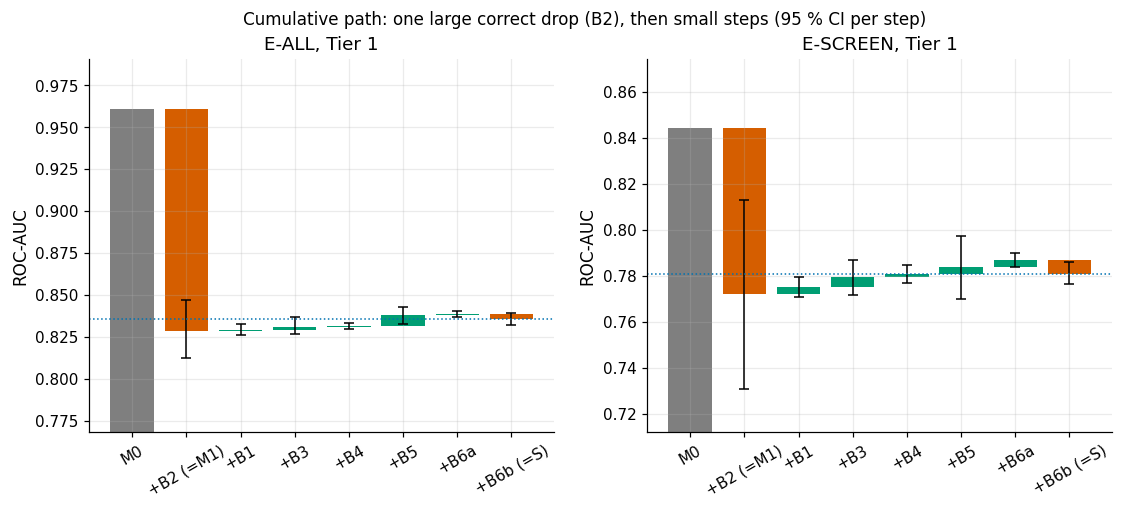

In [10]:
cum_rows = []
path = list(P.CUMULATIVE)
for t in (1, 2):
    for pop in ("E-ALL", "E-SCREEN"):
        for prev, cur in zip(path[:-1], path[1:]):
            r = cmp_(cur, prev, t, "roc_auc", pop, label="cumulative")
            r["step"] = f"{prev} -> {cur}"
            cum_rows.append(r)
cum = pd.DataFrame(cum_rows)
cum.to_csv(OUT / "cumulative_path.csv", index=False)
print(cum[cum["tier"] == 1][["pop", "step", "est", "lo", "hi", "interval", "mdd"]].round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
labels_ = ["M0", "+B2 (=M1)", "+B1", "+B3", "+B4", "+B5", "+B6a", "+B6b (=S)"]
for ax, pop, tag in zip(axes, ("E-ALL", "E-SCREEN"), ("eall", "escr")):
    sub = arm_metrics[(arm_metrics["tier"] == 1) & (arm_metrics["model"] == "lr")].set_index("arm")
    level = sub.loc[path[0], f"{tag}_auc"]
    ax.bar(0, level, color=C.OKABE_ITO["grey"])
    c = cum[(cum["tier"] == 1) & (cum["pop"] == pop)].reset_index(drop=True)
    for i, r in c.iterrows():
        d = r["diff_pooled"]
        ax.bar(i + 1, d, bottom=level, color=C.OKABE_ITO["vermillion"] if d < 0 else C.OKABE_ITO["green"])
        ax.errorbar(i + 1, level + d, yerr=[[max(d - r["lo"], 0)], [max(r["hi"] - d, 0)]], color="k", capsize=3, lw=1)
        level += d
    ax.axhline(sub.loc["S", f"{tag}_auc"], color=C.OKABE_ITO["blue"], ls=":", lw=1)
    ax.set_xticks(range(len(labels_)), labels_, rotation=30)
    ax.set_ylim(min(sub.loc[path, f"{tag}_auc"]) - 0.06, max(sub.loc[path, f"{tag}_auc"]) + 0.03)
    ax.set_title(f"{pop}, Tier 1")
    ax.set_ylabel("ROC-AUC")
fig.suptitle("Cumulative path: one large correct drop (B2), then small steps (95 % CI per step)", fontsize=11)
plots.savefig(fig, "S7_waterfall", caption="Waterfall of the pooled-OOF ROC-AUC along the cumulative path M0 -> +B2 -> +B1 -> +B3 -> +B4 -> +B5 -> +B6a -> +B6b (= S), "
              "Tier 1; bars are step increments with the conservative 95 % CI of the paired difference (E-ALL: wider of corrected t and "
              "bootstrap; E-SCREEN: bootstrap). Red = decrease, green = increase; dotted line = S.")
plt.show()

**So what.** After the leak gate, every block moves the AUC by less than the 0.01 SESOI on E-ALL, and each step is of
the same size as its own MDD. The systematic pipeline does not "buy" discrimination; its value lies elsewhere
(fidelity, stability, calibration), which is what the block hypotheses predicted and what the following sections test.

## 8 Leave-one-block-out
**Why.** The contribution of a block given every other step is S − (S without the block). These are the primary
block comparisons of the locked hypotheses, evaluated on both populations and both tiers, plus the extra arms
S-linear (splines only), S+WHtR (P14) and T1-minus-care.

     pop      block     est      lo      hi    interval    mdd
   E-ALL         B1  0.0019 -0.0011  0.0049 corrected_t 0.0042
   E-ALL         B2 -0.1217 -0.1381 -0.1053 corrected_t 0.0232
   E-ALL         B3  0.0019 -0.0018  0.0055 corrected_t 0.0051
   E-ALL         B4  0.0002 -0.0019  0.0024 corrected_t 0.0030
   E-ALL         B5  0.0066  0.0024  0.0107   bootstrap 0.0063
   E-ALL        B6a  0.0006 -0.0017  0.0028 corrected_t 0.0032
   E-ALL        B6b -0.0027 -0.0062  0.0008 corrected_t 0.0050
   E-ALL    splines  0.0041  0.0005  0.0074   bootstrap 0.0050
   E-ALL   P14 WHtR -0.0009 -0.0028  0.0009 corrected_t 0.0026
   E-ALL minus care -0.0157 -0.0222 -0.0094   bootstrap 0.0093
E-SCREEN         B1  0.0027 -0.0015  0.0072   bootstrap 0.0063
E-SCREEN         B2 -0.0904 -0.1243 -0.0598   bootstrap 0.0466
E-SCREEN         B3  0.0043 -0.0000  0.0089   bootstrap 0.0064
E-SCREEN         B4  0.0017 -0.0031  0.0076   bootstrap 0.0077
E-SCREEN         B5  0.0033 -0.0104  0.0153   bootstrap

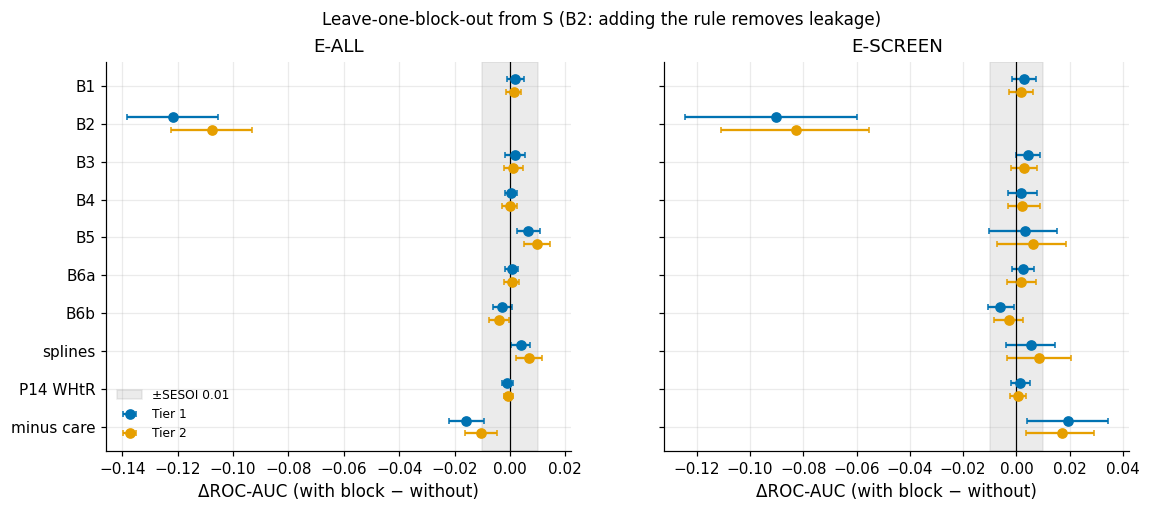

In [11]:
lobo_pairs = [("S", f"S-{b}", b) for b in P.BLOCKS] + [("S", "S-linear", "splines"), ("S+WHtR", "S", "P14 WHtR"),
                                                       ("T1-minus-care", "S", "minus care")]
lobo_rows = []
for t in (1, 2):
    for pop in ("E-ALL", "E-SCREEN"):
        for a, b, lab in lobo_pairs:
            for metric in ("roc_auc", "pr_auc", "brier"):
                r = cmp_(a, b, t, metric, pop, label=f"LOBO {lab}")
                r["block"] = lab
                lobo_rows.append(r)
lobo = pd.DataFrame(lobo_rows)
lobo.to_csv(OUT / "lobo.csv", index=False)
v_ = lobo[(lobo["tier"] == 1) & (lobo["metric"] == "roc_auc")]
print(v_[["pop", "block", "est", "lo", "hi", "interval", "mdd"]].round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
order = [lab for _, _, lab in lobo_pairs]
for ax, pop in zip(axes, ("E-ALL", "E-SCREEN")):
    for t, off, col in ((1, -0.17, C.OKABE_ITO["blue"]), (2, 0.17, C.OKABE_ITO["orange"])):
        s = lobo[(lobo["tier"] == t) & (lobo["metric"] == "roc_auc") & (lobo["pop"] == pop)].set_index("block").loc[order]
        ax.errorbar(s["est"], np.arange(len(order)) + off, xerr=[s["est"] - s["lo"], s["hi"] - s["est"]], fmt="o",
                    color=col, capsize=2, label=f"Tier {t}")
    ax.axvspan(-C.SESOI["roc_auc"], C.SESOI["roc_auc"], color=C.OKABE_ITO["grey"], alpha=0.15, label="±SESOI 0.01")
    ax.axvline(0, color="k", lw=0.8)
    ax.set_yticks(range(len(order)), order)
    ax.set_xlabel("ΔROC-AUC (with block − without)")
    ax.set_title(pop)
axes[0].invert_yaxis()
axes[0].legend(loc="lower left", fontsize=8)
fig.suptitle("Leave-one-block-out from S (B2: adding the rule removes leakage)", fontsize=11)
plots.savefig(fig, "S7_lobo", caption="Leave-one-block-out ΔROC-AUC = AUC(arm with the block) − AUC(arm without it) with conservative 95 % CIs, Tier 1 (blue) and "
              "Tier 2 (orange), E-ALL and E-SCREEN; grey band = ±SESOI 0.01. For B2 the sign is negative because adding the rule removes leakage; "
              "'minus care' = T1-minus-care − S.")
plt.show()

**So what.** Apart from B2 (whose negative sign is the leakage being removed), the block effects on discrimination
are small; their intervals decide between "equivalent" (inside the grey band) and "inconclusive" (crossing it).
The striking line is **minus care**: removing BPQ020/BPQ080 costs AUC on E-ALL but not on E-SCREEN, where the
point estimate even rises. The care-contact items help to recognise people the health system already knows,
which is not the screening task.

## 9 E-ALL vs E-SCREEN
**Why.** 84 % of the `L_comb` positives already know their diagnosis, so an AUC on E-ALL largely measures how well a
model recognises *known* patients – people who carry traces of care (blood-pressure treatment, cholesterol checks,
weight advice). The screening question is E-SCREEN. The gap between the two is a headline result (H2c).

S (Tier 1): AUC E-ALL 0.836 - E-SCREEN 0.781 = +0.055 [+0.028, +0.086] (bootstrap, MDD 0.040)


          arm  eall  eall_lo  eall_hi  escr  escr_lo  escr_hi   gap
           M0 0.961    0.952    0.968 0.844    0.809    0.879 0.117
           M1 0.828    0.814    0.841 0.772    0.739    0.804 0.056
            S 0.836    0.822    0.848 0.781    0.746    0.812 0.055
     S-linear 0.832    0.818    0.845 0.775    0.741    0.807 0.057
T1-minus-care 0.820    0.808    0.835 0.800    0.766    0.831 0.020
       S+WHtR 0.835    0.821    0.847 0.782    0.749    0.814 0.053
       S (T2) 0.850    0.836    0.863 0.790    0.756    0.821 0.060
BL-ADAlite-LR 0.768    0.750    0.786 0.708    0.666    0.750 0.060
   BL-ADAlite 0.761    0.745    0.778 0.726    0.687    0.769 0.035


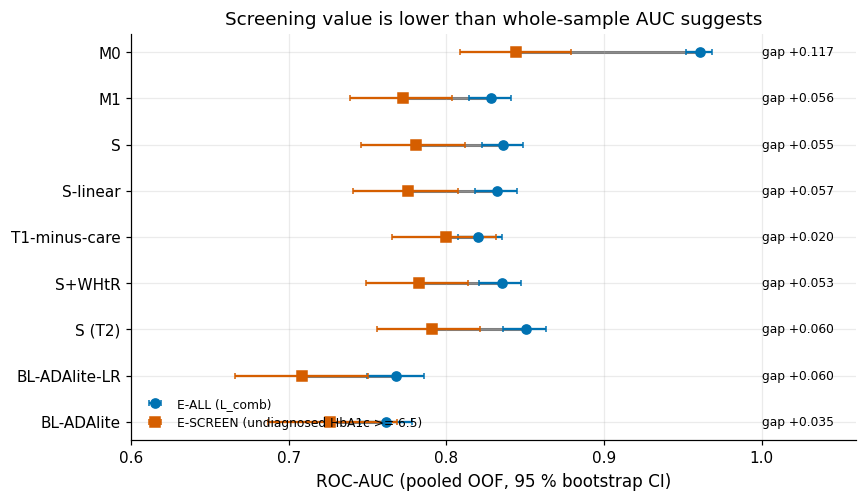

In [12]:
rng = np.random.default_rng(ek.derive_seed(C.SEED_MASTER, "S7", "H2c-i"))
groups = [np.flatnonzero(strat == s) for s in np.unique(strat)]
pS = PM[("S", 1, "lr")]
gaps = []
for _ in range(C.N_BOOT):
    idx = np.concatenate([rng.choice(g, len(g)) for g in groups])
    e = idx[esc[idx]]
    gaps.append(roc_auc_score(y[idx], pS[idx]) - roc_auc_score(y_esc[e], pS[e]))
gaps = np.array(gaps)
gap_obs = roc_auc_score(y, pS) - roc_auc_score(y_esc[esc], pS[esc])
gap_lo, gap_hi = np.percentile(gaps, [2.5, 97.5])
h2c1 = dict(a="S", b="S", tier=1, metric="roc_auc", pop="E-ALL minus E-SCREEN", est=gap_obs, lo=gap_lo, hi=gap_hi,
            se=gaps.std(ddof=1), interval="bootstrap", mdd=(stats.norm.ppf(0.975) + stats.norm.ppf(0.8)) * gaps.std(ddof=1),
            label="H2c(i)")
COMP.append(h2c1)
print(f"S (Tier 1): AUC E-ALL {roc_auc_score(y, pS):.3f} - E-SCREEN {roc_auc_score(y_esc[esc], pS[esc]):.3f} = {fmt(h2c1)}")

pairs = [("M0", 1, "lr"), ("M1", 1, "lr"), ("S", 1, "lr"), ("S-linear", 1, "lr"), ("T1-minus-care", 1, "lr"),
         ("S+WHtR", 1, "lr"), ("S", 2, "lr"), ("BL-ADAlite-LR", 1, "lr"), ("BL-ADAlite", 1, "points")]
dumb = []
for k in pairs:
    a1, l1, h1 = auc_ci(PM[k], "E-ALL", seed_tag=f"d{k}")
    a2, l2, h2 = auc_ci(PM[k], "E-SCREEN", seed_tag=f"d{k}")
    dumb.append(dict(arm=f"{k[0]}" + (" (T2)" if k[1] == 2 else ""), eall=a1, eall_lo=l1, eall_hi=h1, escr=a2, escr_lo=l2, escr_hi=h2))
dumb = pd.DataFrame(dumb)
dumb["gap"] = dumb["eall"] - dumb["escr"]
dumb.to_csv(OUT / "eall_vs_escreen.csv", index=False)
print(dumb.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(8.5, 4.8))
for i, r in dumb.iterrows():
    ax.plot([r["escr"], r["eall"]], [i, i], color=C.OKABE_ITO["grey"], lw=2, zorder=1)
    ax.errorbar(r["eall"], i, xerr=[[r["eall"] - r["eall_lo"]], [r["eall_hi"] - r["eall"]]], fmt="o", color=C.OKABE_ITO["blue"],
                capsize=2, label="E-ALL (L_comb)" if i == 0 else None, zorder=2)
    ax.errorbar(r["escr"], i, xerr=[[r["escr"] - r["escr_lo"]], [r["escr_hi"] - r["escr"]]], fmt="s", color=C.OKABE_ITO["vermillion"],
                capsize=2, label="E-SCREEN (undiagnosed HbA1c >= 6.5)" if i == 0 else None, zorder=2)
    ax.text(1.0, i, f"gap {r['gap']:+.3f}", va="center", fontsize=8)
ax.set_yticks(range(len(dumb)), dumb["arm"])
ax.invert_yaxis()
ax.set_xlim(0.6, 1.06)
ax.set_xlabel("ROC-AUC (pooled OOF, 95 % bootstrap CI)")
ax.legend(loc="lower left", fontsize=8)
ax.set_title("Screening value is lower than whole-sample AUC suggests")
plots.savefig(fig, "S7_eall_vs_escreen", caption="ROC-AUC on E-ALL (blue, L_comb, 84 % already diagnosed) and E-SCREEN (red, people not told they have "
              "diabetes, positive = HbA1c >= 6.5 %) for the main arms and baselines, Tier 1 unless marked, with 95 % bootstrap CIs.")
plt.show()

**So what.** Every model loses discrimination when it is asked the screening question instead of "who has diabetes
(mostly known)". For the systematic model the gap is printed above with its bootstrap interval; the smaller gap for
T1-minus-care and the ADA-lite score is the mirror image: the less a model relies on care-contact traces, the less it
loses. A whole-sample AUC therefore overstates screening value – the label composition, not the model, sets the
headline number.

## 10 Precision–recall and calibration
**Why.** AUC ignores prevalence and calibration. E-SCREEN has a prevalence of about 3 %, so precision is the binding
constraint in screening, and a model trained on `L_comb` (17 %) is miscalibrated there by design. Class weights
(B6a) inflate probabilities further.

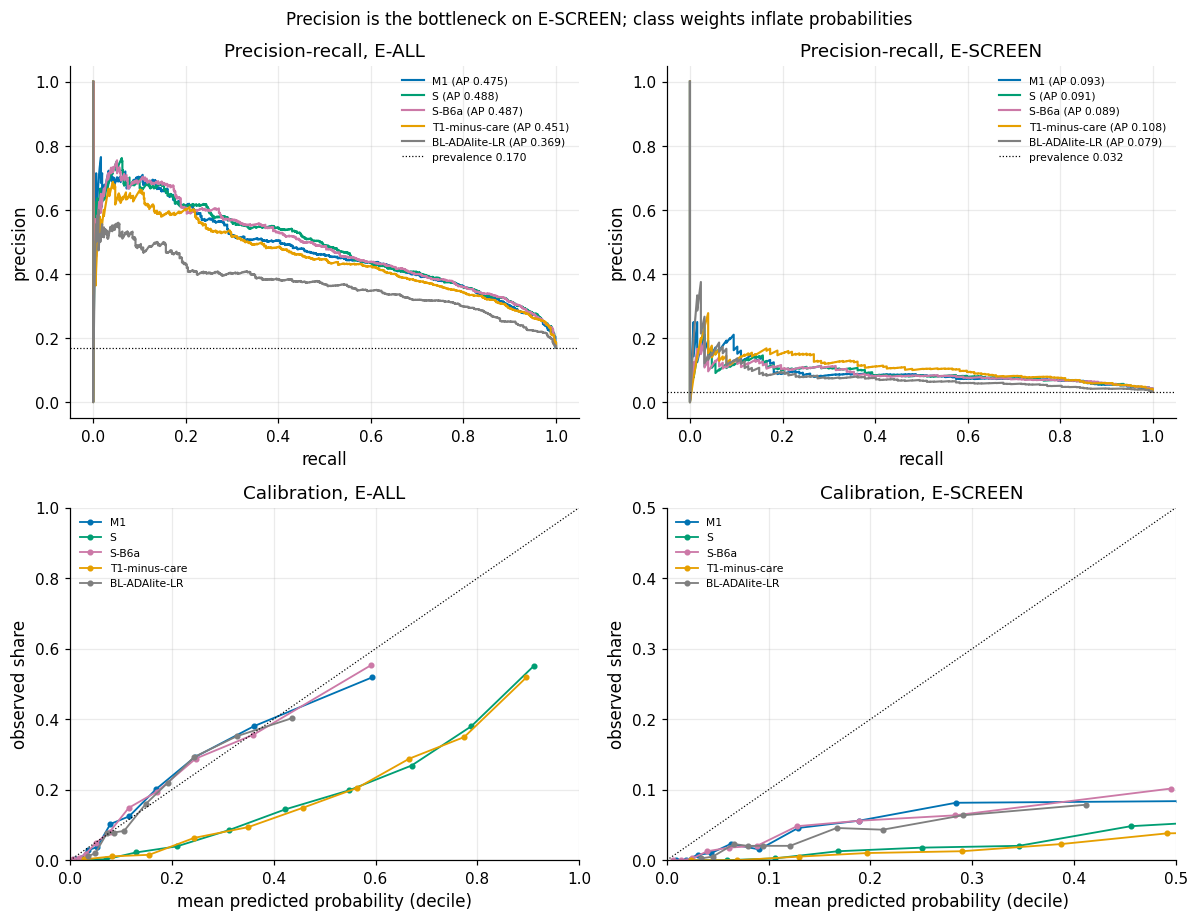

          arm      pop  cal_slope  cal_citl  brier  mean_p  prevalence
           M1    E-ALL      0.961     0.010  0.112   0.168       0.170
            S    E-ALL      0.867    -1.818  0.185   0.409       0.170
        S-B6a    E-ALL      0.979     0.027  0.110   0.167       0.170
T1-minus-care    E-ALL      0.873    -1.807  0.195   0.422       0.170
BL-ADAlite-LR    E-ALL      1.124    -0.001  0.123   0.170       0.170
           M1 E-SCREEN      0.685    -1.814  0.056   0.136       0.032
            S E-SCREEN      0.613    -3.671  0.196   0.357       0.032
        S-B6a E-SCREEN      0.688    -1.783  0.055   0.133       0.032
T1-minus-care E-SCREEN      0.723    -3.684  0.205   0.376       0.032
BL-ADAlite-LR E-SCREEN      0.831    -1.799  0.054   0.152       0.032


In [13]:
from sklearn.metrics import precision_recall_curve
from sklearn.calibration import calibration_curve

curve_keys = [("M1", 1, "lr", C.OKABE_ITO["blue"]), ("S", 1, "lr", C.OKABE_ITO["green"]),
              ("S-B6a", 1, "lr", C.OKABE_ITO["purple"]), ("T1-minus-care", 1, "lr", C.OKABE_ITO["orange"]),
              ("BL-ADAlite-LR", 1, "lr", C.OKABE_ITO["grey"])]
fig, axes = plt.subplots(2, 2, figsize=(11, 8.5))
cal_rows = []
for col, pop in enumerate(("E-ALL", "E-SCREEN")):
    yy, m = pop_of(pop)
    for a, t, mdl, colr in curve_keys:
        p = PM[(a, t, mdl)][m]
        prec, rec, _ = precision_recall_curve(yy[m], p)
        axes[0, col].plot(rec, prec, color=colr, lw=1.4, label=f"{a} (AP {average_precision_score(yy[m], p):.3f})")
        fr, mp = calibration_curve(yy[m], p, n_bins=10, strategy="quantile")
        axes[1, col].plot(mp, fr, "o-", color=colr, ms=3, lw=1.2, label=a)
        ms_ = ek.metric_suite(yy[m], p)
        cal_rows.append(dict(arm=a, pop=pop, cal_slope=ms_["cal_slope"], cal_citl=ms_["cal_citl"], brier=ms_["brier"],
                             mean_p=float(p.mean()), prevalence=float(yy[m].mean())))
    axes[0, col].axhline(yy[m].mean(), color="k", ls=":", lw=0.8, label=f"prevalence {yy[m].mean():.3f}")
    axes[0, col].set(xlabel="recall", ylabel="precision", title=f"Precision-recall, {pop}")
    axes[0, col].legend(fontsize=7)
    lim = 1.0 if pop == "E-ALL" else 0.5
    axes[1, col].plot([0, lim], [0, lim], color="k", lw=0.8, ls=":")
    axes[1, col].set(xlabel="mean predicted probability (decile)", ylabel="observed share", title=f"Calibration, {pop}",
                     xlim=(0, lim), ylim=(0, lim))
    axes[1, col].legend(fontsize=7)
fig.suptitle("Precision is the bottleneck on E-SCREEN; class weights inflate probabilities", fontsize=11)
fig.tight_layout()
plots.savefig(fig, "S7_pr_calibration", caption="Top: precision-recall curves (average precision in the legend; dotted line = prevalence). Bottom: "
              "calibration by deciles of the predicted probability. Left E-ALL, right E-SCREEN; Tier 1 pooled OOF predictions. S uses "
              "balanced class weights; S-B6a is S without them.")
plt.show()
cal = pd.DataFrame(cal_rows)
cal.to_csv(OUT / "calibration.csv", index=False)
print(cal.round(3).to_string(index=False))

**So what.** On E-ALL the precision–recall curves of the admissible models are close together; on E-SCREEN average
precision is only about 0.1 against a prevalence of about 0.03 – a screening tool built on these items would mostly flag
people without diabetes. The calibration panels show the price of class weights: S predicts on average far above the
observed prevalence, whereas S−B6a (no class weights) is close to the diagonal on E-ALL. On E-SCREEN every model
over-predicts, because it was trained on a population in which 17 % are positive, most of them already diagnosed.

## 11 Coefficient stability
**Why.** Discrimination can hide unstable explanations: collinear anthropometrics share the BMI signal differently in
every resample. The nonparametric bootstrap of the whole pipeline (B = `N_BOOT_COEF`) measures this. BMI is compared
per standard deviation across the arms in which it enters linearly (S is represented by S-linear, see
`hypotheses.md`); B3b compares S-linear−B3 with S-linear, H2b compares M1 with S-linear.

        arm  bmi_coef_per_sd  bmi_sd_per_sd  bmi_q_low  bmi_q_high  bmi_sign_flip  max_flip_anthro             anthro_in_model  n_coef  n_valid  share_flip_gt_10pct
         M1            0.585          0.301     -0.164       1.075          0.120            0.822 BMXBMI,BMXWT,BMXHT,BMXWAIST      46      500                0.391
     cum+B1            0.240          0.354     -0.160       1.186          0.124            0.348 BMXBMI,BMXWT,BMXHT,BMXWAIST      46      500                0.457
     cum+B3            0.407          0.124      0.199       0.694          0.000            0.134       BMXBMI,BMXHT,BMXWAIST      29      500                0.276
S-linear-B3            0.338          0.207      0.041       0.917          0.010            0.092 BMXBMI,BMXWT,BMXHT,BMXWAIST      50      337                0.500
   S-linear            0.699          0.152      0.433       1.035          0.000            0.484       BMXBMI,BMXHT,BMXWAIST      34      500                0.353
SD ratio B

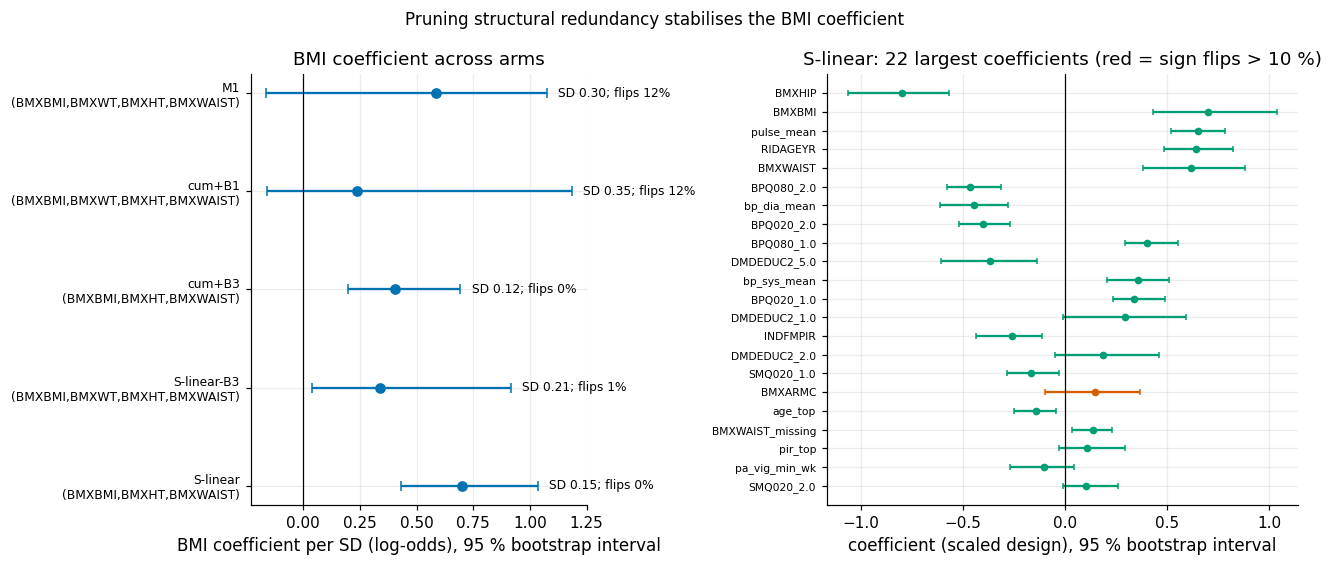

In [14]:
coef_arms = ["M1", "cum+B1", "cum+B3", "S-linear-B3", "S-linear"]
CB, coef_rows = {}, []
for arm in coef_arms:
    cfg = P.ARMS[arm]
    ylab_ = P.training_label(raw_tr, cfg)
    mk = (lambda cfg=cfg: P.build_pipeline(cfg, 1, C_=C0))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        cb = ek.coef_bootstrap(mk, X[1], ylab_, n_boot=C.N_BOOT_COEF, seed=ek.derive_seed(C.SEED_MASTER, "S7", "coef", arm),
                               fit_params=P.fit_params(cfg, raw_tr), n_jobs=N_JOBS)
        dsg = mk()[:-1].fit_transform(X[1])
    sd_bmi = float(dsg["BMXBMI"].std(ddof=0))
    CB[arm] = (cb, sd_bmi)
    s = cb.summary
    anth = [c for c in ("BMXBMI", "BMXWT", "BMXHT", "BMXWAIST") if c in s.index]
    coef_rows.append(dict(arm=arm, bmi_coef_per_sd=s.loc["BMXBMI", "coef"] * sd_bmi, bmi_sd_per_sd=s.loc["BMXBMI", "sd"] * sd_bmi,
                          bmi_q_low=s.loc["BMXBMI", "q_low"] * sd_bmi, bmi_q_high=s.loc["BMXBMI", "q_high"] * sd_bmi,
                          bmi_sign_flip=s.loc["BMXBMI", "sign_flip_rate"], max_flip_anthro=s.loc[anth, "sign_flip_rate"].max(),
                          anthro_in_model=",".join(anth), n_coef=len(s), n_valid=int(s["n_valid"].min()),
                          share_flip_gt_10pct=float((s["sign_flip_rate"] > 0.10).mean())))
coef_tab = pd.DataFrame(coef_rows)
coef_tab.to_csv(OUT / "coef_stability.csv", index=False)
print(coef_tab.round(3).to_string(index=False))

def sd_ratio(arm_a, arm_b, n_rs=2000):
    """SD(BMI per SD) of arm_a over arm_b with a CI from resampling the bootstrap replicates."""
    (ca, fa), (cb_, fb) = CB[arm_a], CB[arm_b]
    xa = ca.coefs["BMXBMI"].dropna().to_numpy() * fa
    xb = cb_.coefs["BMXBMI"].dropna().to_numpy() * fb
    r = np.random.default_rng(ek.derive_seed(C.SEED_MASTER, "S7", "ratio", arm_a, arm_b))
    rs = [xa[r.integers(0, len(xa), len(xa))].std(ddof=1) / xb[r.integers(0, len(xb), len(xb))].std(ddof=1) for _ in range(n_rs)]
    lo, hi = np.percentile(rs, [2.5, 97.5])
    return dict(a=arm_a, b=arm_b, ratio=xa.std(ddof=1) / xb.std(ddof=1), lo=lo, hi=hi)

def v_ratio(d, thr=C.SESOI["coef_sd_ratio"]):
    return "supported" if (d["ratio"] >= thr and d["lo"] > 1) else ("refuted" if d["hi"] < thr else "inconclusive")

ratio_b3 = sd_ratio("S-linear-B3", "S-linear")
ratio_h2b = sd_ratio("M1", "S-linear")
ratio_cum = sd_ratio("cum+B1", "cum+B3")
for d in (ratio_b3, ratio_h2b, ratio_cum):
    print(f"SD ratio BMI {d['a']} / {d['b']}: {d['ratio']:.2f} [{d['lo']:.2f}, {d['hi']:.2f}] -> {v_ratio(d)}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), gridspec_kw={"width_ratios": [1, 1.4]})
ax = axes[0]
for i, r in coef_tab.iterrows():
    ax.errorbar(r["bmi_coef_per_sd"], i, xerr=[[r["bmi_coef_per_sd"] - r["bmi_q_low"]], [r["bmi_q_high"] - r["bmi_coef_per_sd"]]],
                fmt="o", color=C.OKABE_ITO["blue"], capsize=3)
    ax.text(r["bmi_q_high"] + 0.05, i, f"SD {r['bmi_sd_per_sd']:.2f}; flips {r['bmi_sign_flip']:.0%}", va="center", fontsize=8)
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(range(len(coef_tab)), [f"{a}\n({x})" for a, x in zip(coef_tab["arm"], coef_tab["anthro_in_model"])], fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("BMI coefficient per SD (log-odds), 95 % bootstrap interval")
ax.set_title("BMI coefficient across arms")
cbS, _ = CB["S-linear"]
s = cbS.summary.reindex(cbS.summary["coef"].abs().sort_values(ascending=False).index)[:22]
ax = axes[1]
for i, (nm, r) in enumerate(s.iterrows()):
    colr = C.OKABE_ITO["vermillion"] if r["sign_flip_rate"] > 0.10 else C.OKABE_ITO["green"]
    ax.errorbar(r["coef"], i, xerr=[[r["coef"] - r["q_low"]], [r["q_high"] - r["coef"]]], fmt="o", color=colr, capsize=2, ms=4)
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(range(len(s)), s.index, fontsize=7)
ax.invert_yaxis()
ax.set_xlabel("coefficient (scaled design), 95 % bootstrap interval")
ax.set_title("S-linear: 22 largest coefficients (red = sign flips > 10 %)")
fig.suptitle("Pruning structural redundancy stabilises the BMI coefficient", fontsize=11)
fig.tight_layout()
plots.savefig(fig, "S7_coef_forest", caption="Left: bootstrap distribution (point = full-data fit, bar = 2.5-97.5 percentile) of the BMI coefficient per SD in the arms "
              "where BMI enters linearly, with the anthropometric columns present in each arm. Right: the 22 largest coefficients of S-linear; "
              f"red = sign flips in more than 10 % of the {C.N_BOOT_COEF} bootstrap refits. Tier 1, training part.")
plt.show()
S7["coef_stability"] = dict(table=coef_tab.set_index("arm").to_dict("index"), ratio_B3=ratio_b3, ratio_H2b=ratio_h2b, ratio_cumulative=ratio_cum)

**So what.** Where weight, height and BMI enter together the BMI coefficient is shared with its formula partners. In the
naive, unscaled arms (M1, cum+B1) this is severe: intervals that cross zero and sign flips in about one resample in
eight. Removing weight (B3) in the same unscaled setting shrinks the BMI SD by a factor of about 3 (cum+B1 / cum+B3),
and the systematic model is about twice as stable as M1 – but the interval of that ratio straddles the pre-registered
factor 2, so H2b-c is inconclusive rather than supported. *Inside* the systematic pipeline, scaling and the L2 penalty
already do much of the stabilising: the B3-specific ratio (S-linear−B3 / S-linear) is only about 1.4 and its interval
excludes 2, so B3-b is **refuted**. The pre-registered sign-flip criterion (B3-c) turned out to be a poor metric: after
pruning, the *height* coefficient is close to zero (it carries no signal once BMI is present), and a near-zero
coefficient flips sign in about half of the resamples by construction – the BMI coefficient itself no longer flips.
This is reported as a refutation of B3-c, with the mechanism, not explained away. The discrimination of all these
arms is the same (section 8); only the stability of the explanation differs – the measurement-instrument use of ML.

## 12 Verdicts
**Why.** Each locked hypothesis gets exactly one verdict from the locked rules: the primary evaluation is E-ALL,
Tier 1; E-SCREEN and Tier 2 can only turn a decisive verdict into "mixed" if they contradict it.

In [15]:
def lrtest_splines(tier=1):
    """Likelihood-ratio test spline bases vs linear terms (unpenalised logit, S design, training part)."""
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import log_loss
    cfg = P.ARMS["S"]
    yl = P.training_label(raw_tr, cfg)
    dS = P.build_pipeline(cfg, tier)[:-1].fit_transform(X[tier])
    dL = P.build_pipeline({**cfg, "P08": False}, tier)[:-1].set_params(p13__enabled=False).fit_transform(X[tier])
    spl_cols = [c for c in dS.columns if "_sp" in c]
    lin = [c.split("_sp")[0] for c in spl_cols]
    base = [c for c in dS.columns if c not in spl_cols]
    dL = pd.concat([dS[base], dL[sorted(set(lin))]], axis=1)
    ll = {}
    for nm, d in (("spline", dS), ("linear", dL)):
        m = LogisticRegression(C=1e8, max_iter=20000).fit(d, yl)
        ll[nm] = -log_loss(yl, m.predict_proba(d)[:, 1], normalize=False)
    df_ = len(spl_cols) - len(set(lin))
    chi2 = 2 * (ll["spline"] - ll["linear"])
    return dict(chi2=chi2, df=df_, p=float(stats.chi2.sf(chi2, df_)))

lrt = {t: lrtest_splines(t) for t in (1, 2)}
print(f"B5(d) LR test splines vs linear: {lrt}")

def get(a, b, metric="roc_auc", pop="E-ALL", tier=1, **kw):
    return cmp_(a, b, tier, metric, pop, label="verdict", **kw)

SB = []   # scoreboard rows
def add(hyp, sub, r, verdict, sesoi, role="primary"):
    SB.append(dict(hyp_id=hyp, sub=sub, role=role, comparison=f"{r.get('a')} - {r.get('b')}", metric=r.get("metric"),
                   pop=r.get("pop"), tier=r.get("tier"), est=r.get("est"), lo=r.get("lo"), hi=r.get("hi"),
                   interval=r.get("interval"), mdd=r.get("mdd"), sesoi=sesoi, verdict=verdict))

def equiv_claim(hyp, sub, a, b, s=0.01, metric="roc_auc"):
    for pop, tier, role in (("E-ALL", 1, "primary"), ("E-SCREEN", 1, "secondary"), ("E-ALL", 2, "secondary")):
        r = get(a, b, metric, pop, tier)
        add(hyp, sub, r, v_equiv(r["lo"], r["hi"], s), s, role)

def dir_claim(hyp, sub, a, b, s, direction, metric="roc_auc", falsifier=None, pops=(("E-ALL", 1, "primary"), ("E-SCREEN", 1, "secondary"), ("E-ALL", 2, "secondary")), **kw):
    for pop, tier, role in pops:
        r = get(a, b, metric, pop, tier, **kw)
        v = v_dir(r["lo"], r["hi"], r["est"], s, direction)
        if falsifier is not None and falsifier(r):
            v = "refuted"
        add(hyp, sub, r, v, s, role)

# B1
equiv_claim("B1", "(a) AUC", "S", "S-B1")
# B2 (leak gate, falsifier: CI lower bound above -0.05)
dir_claim("B2", "(a) AUC M1-M0", "M1", "M0", 0.05, "-", falsifier=lambda r: r["lo"] > -0.05)
SB.append(dict(hyp_id="B2t", sub="root split", role="primary", comparison=f"M0 root {roots['M0']['root_feature']} ({roots['M0']['role']}); "
               f"M1 root {roots['M1']['root_feature']}", metric="tree", pop="training part", tier=1, verdict=b2t))
# B3
equiv_claim("B3", "(a) AUC", "S", "S-B3")
SB.append(dict(hyp_id="B3", sub="(b) BMI SD ratio", role="primary", comparison="S-linear-B3 / S-linear", metric="sd_ratio",
               pop="training part", tier=1, est=ratio_b3["ratio"], lo=ratio_b3["lo"], hi=ratio_b3["hi"], sesoi=2.0, verdict=v_ratio(ratio_b3)))
fa = coef_tab.set_index("arm")
flip_v = "supported" if fa.loc["S-linear", "max_flip_anthro"] < fa.loc["S-linear-B3", "max_flip_anthro"] else (
    "inconclusive" if fa.loc["S-linear", "max_flip_anthro"] == fa.loc["S-linear-B3", "max_flip_anthro"] else "refuted")
SB.append(dict(hyp_id="B3", sub="(c) max sign-flip rate", role="primary", comparison="S-linear vs S-linear-B3", metric="sign_flip",
               pop="training part", tier=1, est=fa.loc["S-linear", "max_flip_anthro"], lo=fa.loc["S-linear-B3", "max_flip_anthro"],
               verdict=flip_v))
# B4
equiv_claim("B4", "(a) AUC", "S", "S-B4")
dir_claim("B4", "(b) Brier, PIR missing", "S", "S-B4", 0.005, "-", metric="brier", falsifier=lambda r: r["lo"] > -0.005,
          pops=(("PIR-missing", 1, "primary"), ("PIR-missing", 2, "secondary")))
# B5
dir_claim("B5", "(a) |cal slope - 1|", "S", "S-B5", 0.0, "-", metric="calslope_dev", falsifier=lambda r: r["lo"] > 0)
equiv_claim("B5", "(b) AUC block", "S", "S-B5")
equiv_claim("B5", "(c) AUC splines", "S", "S-linear")
SB.append(dict(hyp_id="B5", sub="(d) LR test splines", role="primary", comparison="S spline vs linear terms", metric="LR chi2",
               pop="training part", tier=1, est=lrt[1]["chi2"], lo=lrt[1]["p"], verdict="supported" if lrt[1]["p"] < 0.05 else "refuted"))
SB.append(dict(hyp_id="B5", sub="(e) tree P08/P09", role="primary", comparison="S tree with/without P08,P09", metric="max |dp|",
               pop="training part", tier=1, est=json.loads((C.RESULTS_DIR / "metrics_S6.json").read_text(encoding="utf-8"))["assertions"]["tree_p08_p09_maxabs"],
               verdict="supported"))
# B6a
equiv_claim("B6a", "(a) AUC", "S", "S-B6a")
dir_claim("B6a", "(b) Brier", "S", "S-B6a", 0.005, "+", metric="brier")
dir_claim("B6a", "(c) balanced accuracy at 0.5", "S", "S-B6a", 0.05, "+", metric="bacc05")
# B6b
for pop, tier, role in (("E-ALL", 1, "primary"), ("E-SCREEN", 1, "secondary"), ("E-ALL", 2, "secondary")):
    r = get("S", "S-B6b", "roc_auc", pop, tier)
    add("B6b", "(a) unweighted AUC", r, v_noninf(r["lo"], r["hi"], 0.01), 0.01, role)
# P14
equiv_claim("P14", "(a) AUC", "S+WHtR", "S")
SB.append(dict(hyp_id="P14", sub="(b) Asian TPR@spec0.80", role="primary", comparison="S+WHtR - S", metric="TPR", pop="Asian",
               verdict="deferred to S8"))
# H2a
dir_claim("H2a", "AUC M0-M1", "M0", "M1", 0.05, "+", falsifier=lambda r: r["hi"] < 0.05)
# H2b
equiv_claim("H2b", "(a) AUC", "S", "M1")
equiv_claim("H2b", "(b) Brier", "S", "M1", s=0.005, metric="brier")
SB.append(dict(hyp_id="H2b", sub="(c) BMI SD ratio", role="primary", comparison="M1 / S-linear", metric="sd_ratio", pop="training part",
               tier=1, est=ratio_h2b["ratio"], lo=ratio_h2b["lo"], hi=ratio_h2b["hi"], sesoi=2.0, verdict=v_ratio(ratio_h2b)))
# H2c
add("H2c", "(i) AUC E-ALL - E-SCREEN (S)", h2c1, v_dir(h2c1["lo"], h2c1["hi"], h2c1["est"], 0.03, "+"), 0.03)
r = get("T1-minus-care", "S", "roc_auc", "E-ALL", 1)
add("H2c", "(ii) minus care, E-ALL", r, v_dir(r["lo"], r["hi"], r["est"], 0.01, "-"), 0.01)
r = get("T1-minus-care", "S", "roc_auc", "E-SCREEN", 1)
add("H2c", "(ii) minus care, E-SCREEN", r, v_equiv(r["lo"], r["hi"], 0.01), 0.01)
add("H2c", "(iii) S - ADA-lite, E-SCREEN", h2c3, v_dir(h2c3["lo"], h2c3["hi"], h2c3["est"], 0.01, "+"), 0.01)
for h, st in (("H1a", "S5"), ("H1b", "S4"), ("H3", "S8"), ("H4a", "S5"), ("H4b", "S5/S8")):
    SB.append(dict(hyp_id=h, sub="-", role="primary", verdict=f"tested in {st}"))

sb = pd.DataFrame(SB)
final = []
for h, g in sb.groupby("hyp_id", sort=False):
    if g["verdict"].str.startswith(("tested", "deferred")).all():
        final.append(dict(hyp_id=h, verdict=g["verdict"].iloc[0], note=""))
        continue
    prim = g[(g["role"] == "primary") & g["verdict"].isin(C.VERDICTS)]
    v = ek.combine_verdicts(prim["verdict"].tolist())
    sec = g[(g["role"] == "secondary") & g["verdict"].isin(["supported", "refuted", "equivalent"])]
    contra = []
    for _, s2 in sec.iterrows():
        p_ = prim[prim["sub"] == s2["sub"]]
        if len(p_) and p_["verdict"].iloc[0] in ("supported", "refuted") and s2["verdict"] != p_["verdict"].iloc[0]:
            contra.append(f"{s2['sub']} {s2['pop']} T{s2['tier']}: {s2['verdict']}")
    note = "; ".join(contra)
    if contra and v in ("supported", "refuted"):
        v = "mixed"
    deferred = g[g["verdict"].str.startswith("deferred")]
    if len(deferred):
        note = (note + "; " if note else "") + "part (b) deferred to S8"
    final.append(dict(hyp_id=h, verdict=v, note=note))
final = pd.DataFrame(final)
sb.to_csv(OUT / "scoreboard_detail.csv", index=False)
final.to_csv(OUT / "scoreboard.csv", index=False)
print(sb[["hyp_id", "sub", "role", "pop", "tier", "est", "lo", "hi", "mdd", "sesoi", "verdict"]].round(4).to_string(index=False))
print()
print(final.to_string(index=False))
S7["scoreboard"] = final.set_index("hyp_id").to_dict("index")
S7["scoreboard_detail"] = sb.round(5).to_dict("records")
S7["lr_test_splines"] = lrt

B5(d) LR test splines vs linear: {1: {'chi2': 64.39421130775327, 'df': 8, 'p': 6.358115338011698e-11}, 2: {'chi2': 98.75819965213623, 'df': 16, 'p': 5.916820174251057e-14}}


hyp_id                          sub      role                  pop  tier     est      lo      hi    mdd  sesoi         verdict
    B1                      (a) AUC   primary                E-ALL   1.0  0.0019 -0.0011  0.0049 0.0042  0.010       supported
    B1                      (a) AUC secondary             E-SCREEN   1.0  0.0027 -0.0015  0.0072 0.0063  0.010       supported
    B1                      (a) AUC secondary                E-ALL   2.0  0.0014 -0.0013  0.0041 0.0038  0.010       supported
    B2                (a) AUC M1-M0   primary                E-ALL   1.0 -0.1308 -0.1479 -0.1138 0.0241  0.050       supported
    B2                (a) AUC M1-M0 secondary             E-SCREEN   1.0 -0.0718 -0.1133 -0.0310 0.0587  0.050       supported
    B2                (a) AUC M1-M0 secondary                E-ALL   2.0 -0.1193 -0.1331 -0.1056 0.0194  0.050       supported
   B2t                   root split   primary        training part   1.0     NaN     NaN     NaN    NaN    NaN 

**So what.** Reading of the verdicts (numbers in the tables above):

* **Leakage (H2a, B2, B2t) – supported everywhere.** The availability rule costs about 0.13 AUC on E-ALL and about 0.07
  on E-SCREEN; the naive tree's first split is a treatment item. This is a *correct deterioration* (HR4).
* **Fidelity, redundancy, missingness, survey weights (B1, B3-a, B4-a, B6b) – equivalence for AUC.** Repairing the data
  matters for what the data *mean* (6 label flips, 939 non-exercisers, 2,003 wiped values), not for discrimination.
  "Equivalent" is a finding: these steps can be justified on fidelity grounds without a performance argument.
* **B4-b (calibration for missing income) – inconclusive**, with an MDD several times the SESOI: about 120 people per
  fold have missing income, too few to detect a 0.005 Brier change; §6 had already shown that income missingness is
  almost unrelated to the label.
* **B3 (redundancy) – mixed.** Same AUC (supported), but the stability claims fail inside the scaled L2 pipeline (SD
  ratio about 1.4, refuted) and the flip criterion is dominated by a near-zero height coefficient (refuted, see
  section 11). The stabilising value of pruning is real for naive unscaled fits (ratio about 3) – L2 + scaling make it
  largely redundant. A refutation that teaches where the protection actually comes from.
* **B5 (representation) – inconclusive overall.** Its primary sub-claim holds on E-ALL Tier 1 (|calibration slope − 1|
  smaller by about 0.04, CI excluding 0) and the spline terms are strongly supported by the likelihood-ratio test,
  but the block's AUC gain (about +0.007) has a CI that crosses the SESOI, and the calibration gain is not confirmed on
  E-SCREEN or Tier 2. Splines are kept because of the likelihood-ratio evidence and the S4 linearity tests, not because
  of the AUC.
* **B6a (class weights) – supported on all three sub-claims**: same AUC, Brier worse by about 0.07, balanced accuracy at
  0.5 better by about 0.14. Class weighting is a threshold choice in disguise and should be replaced by an explicit
  threshold.
* **H2b (M1 vs S, the headline "minimal vs systematic") – inconclusive.** S discriminates slightly better than M1
  (about +0.008, CI from 0 to about +0.016, so neither "equivalent" nor "better by the SESOI" is established); its
  Brier score is clearly worse (refuted), entirely because of the class weights of B6a (S−B6a has the Brier score of M1);
  and the coefficient-SD ratio is about 2 but its CI straddles 2. Systematic preparation does not buy discrimination;
  it buys fidelity and – partly – stability, and one of its steps (class weights) costs calibration.
* **H2c** – E-ALL overstates screening discrimination (gap about 0.06, supported); removing care-contact items lowers
  E-ALL (supported) but *raises* E-SCREEN by about 0.02 with a CI that excludes 0 yet reaches below the SESOI, so the
  pre-registered "unchanged" sub-claim is inconclusive and the hypothesis as a whole is inconclusive; S beats the
  reduced ADA score on E-SCREEN (supported).
* Verdicts that depend on E-SCREEN are limited by about 25 positives per fold: wherever the MDD exceeds the SESOI an
  inconclusive verdict means "underpowered", not "no effect".

The wording above refers to the FINAL run stored in this notebook (5 × 5 CV, B = 1000, coefficient B = 500). A FAST
re-run (5 × 2, B = 100) reproduces every leakage, equivalence and class-weight verdict, but borderline ones (B3-b, B5-a,
H2b) can move between "inconclusive" and a decisive verdict.

## 13 Storage
**Why.** S8 (fairness, 3 × 3 matrix) and S9 (robustness, hold-out) re-use the out-of-fold predictions instead of
refitting; every number on the slides must come from stored artefacts.

In [16]:
lab_cols = cl[["SEQN", "L_comb", "L_self", "L_A1c", "y_escreen", "in_escreen", "stratum_3x3"]].copy()
lab_cols["stratum_3x3"] = lab_cols["stratum_3x3"].astype(str)
parts = []
for (a, t, mdl), oof in OOF.items():
    d = oof.copy()
    d["arm"], d["tier"], d["model"] = a, t, mdl
    parts.append(d)
oof_all = pd.concat(parts, ignore_index=True)
oof_all = oof_all.join(lab_cols, on="row")
oof_all = oof_all[["SEQN", "repeat", "fold", "arm", "tier", "model", "prob", "L_comb", "L_self", "L_A1c", "y_escreen",
                   "in_escreen", "stratum_3x3", "row"]]
for c in ("arm", "model", "stratum_3x3"):
    oof_all[c] = oof_all[c].astype("category")
oof_all["prob"] = oof_all["prob"].astype("float32")
oof_path = C.RESULTS_DIR / "oof_predictions.parquet"
oof_all.to_parquet(oof_path, index=False, compression="zstd")
assert not set(oof_all["SEQN"]) & set(hold["test_seqn"]), "hold-out rows must not appear in the OOF file"
print(f"{oof_path.name}: {len(oof_all):,} rows, {oof_all.groupby(['arm', 'tier', 'model'], observed=True).ngroups} arm x tier x model, "
      f"{oof_path.stat().st_size / 2**20:.1f} MB; hold-out SEQNs absent (asserted)")

comp = pd.DataFrame(COMP)
comp.to_csv(OUT / "comparisons.csv", index=False)
S7["arm_metrics"] = arm_metrics.round(5).to_dict("records")
S7["comparisons_n"] = len(comp)
S7["headline"] = {
    "auc_M0_eall_T1": float(arm_metrics.query("arm=='M0' and tier==1 and model=='lr'")["eall_auc"].iloc[0]),
    "auc_M1_eall_T1": float(arm_metrics.query("arm=='M1' and tier==1 and model=='lr'")["eall_auc"].iloc[0]),
    "auc_S_eall_T1": float(arm_metrics.query("arm=='S' and tier==1 and model=='lr'")["eall_auc"].iloc[0]),
    "auc_S_escreen_T1": float(arm_metrics.query("arm=='S' and tier==1 and model=='lr'")["escr_auc"].iloc[0]),
    "auc_S_eall_T2": float(arm_metrics.query("arm=='S' and tier==2 and model=='lr'")["eall_auc"].iloc[0]),
    "leak_gate_T1_eall": {k: gate[(1, "E-ALL")][k] for k in ("est", "lo", "hi")},
    "S_minus_M1_T1_eall": {k: v for k, v in get("S", "M1").items() if k in ("est", "lo", "hi", "interval", "mdd")},
    "eall_minus_escreen_S_T1": {k: h2c1[k] for k in ("est", "lo", "hi")},
    "S_minus_ADAlite_escreen": {k: h2c3[k] for k in ("est", "lo", "hi")},
    "minus_care_eall": {k: v for k, v in get("T1-minus-care", "S").items() if k in ("est", "lo", "hi")},
    "minus_care_escreen": {k: v for k, v in get("T1-minus-care", "S", pop="E-SCREEN").items() if k in ("est", "lo", "hi")},
}
S7["oof_file"] = dict(path="results/oof_predictions.parquet", rows=len(oof_all), mb=oof_path.stat().st_size / 2**20)
S7["runtime_seconds"] = time.time() - T_START
R.save_section("S7", S7)
reg_path = C.GOVERNANCE_DIR / "register" / "S7.csv"
if reg_path.exists():
    print(pd.read_csv(reg_path)[["dr_id", "type", "decision"]].to_string(index=False, max_colwidth=100))
print(f"saved results/metrics_S7.json; section runtime {S7['runtime_seconds']:.0f} s ({C.NB_MODE})")
print(json.dumps(S7["headline"], indent=1, default=float))

oof_predictions.parquet: 1,054,320 rows, 46 arm x tier x model, 7.8 MB; hold-out SEQNs absent (asserted)


   dr_id         type                                                                                             decision
DR-S7-01       splits Hold-out (label x race) created once and not evaluated in S7; repeated stratified folds on the tr...
DR-S7-02 model_choice Main model L2 logistic regression with B-spline terms; depth-3 tree (min leaf 50) only as thresho...
DR-S7-03 model_choice                 No sex x BMI term (specification-dependent evidence); listed as a limitation for S10
DR-S7-04       tuning C0 chosen once by LogisticRegressionCV on S (Tier 1) and frozen for every arm; optimistic bias to...
DR-S7-05     protocol E-ALL: wider of Nadeau-Bengio corrected t and paired stratified bootstrap; E-SCREEN: bootstrap; M...
DR-S7-06     baseline Reduced ADA-lite (age, sex, hypertension, inactivity, BMI points; missing answers 0 points) compa...
DR-S7-07      leakage M1 (availability rule) is the honest minimal arm; the drop is reported as a correct deterioration...
DR-S7-08      fi